# Custom Transformer

In [1]:
import pandas as pd
import seaborn as sns

👉 We will be using this dataset:

In [2]:
data = pd.read_csv("https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/08-Workflow/custom_transformer_data.csv")
data.head()

,customer_state,seller_state,product_weight_g,product_length_cm,product_height_cm,product_width_cm,days_until_delivery
0,RJ,SP,1825,53,10,40,9
1,RJ,SP,700,65,18,28,9
2,RJ,SP,1825,53,10,40,11
3,RJ,SP,1825,53,10,40,12
4,RJ,SP,1825,53,10,40,14


In [3]:
# Dealing with duplicates

data.duplicated().sum()
data = data.drop_duplicates()

In [4]:
# Checking null

data.isnull().sum()

customer_state         0
seller_state           0
product_weight_g       0
product_length_cm      0
product_height_cm      0
product_width_cm       0
days_until_delivery    0
dtype: int64

- Each observation of the dataset represents an item being delivered from a  `seller_state` to a `customer_state`. 
- Other columns describe the packaging properties of each item.

🎯 The target is the number of days between the order and the delivery.

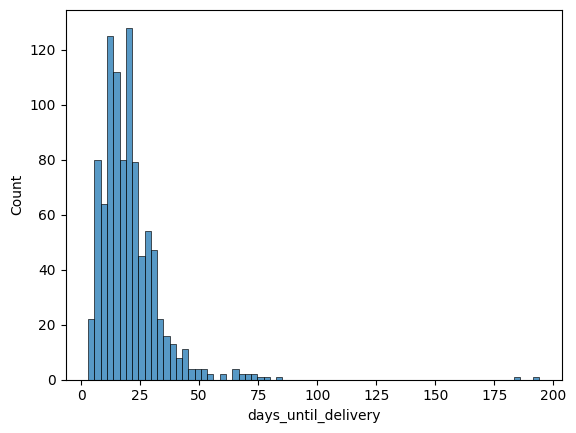

In [5]:
# Check target
sns.histplot(data.days_until_delivery);

## 1. Pipeline

👉 Create a scikit-learn pipeline named `pipe`:

- Engineer a `volume` feature from the dimensions features
- Keep the original product dimensions features for training
- Scale all numerical features
- Encode the categorical features
- Add a default `Ridge` regression estimator

**Note:** hold out a test set first with `train_test_split(X, y, test_size=0.2, random_state=42)`.  
⚠️ Fit and test your pipeline on `X_train`/`y_train` only, never on the full `X`/`y`.

<details><summary><strong>Hints</strong></summary>

- There are many ways to create your preprocessed matrix (using `ColumnTransformer` and/or `FeatureUnion`). 
    
- If your transformed feature matrix look weird, it may be stored as "sparse" by the default behavior of `OneHotEncoder(sparse_output=True)`. Use `.todense()` to turn it back to a dense matrix.

- Use `.set_output(transform='pandas')` on your final pipeline to output a Pandas DataFrame with column names instead of the default NumPy array. (No need to set it on each individual transformer. If you set it on the pipeline, it will pass it on to the substages.)

</details>

<br>

<details><summary><strong>More hints: step-by-step guidance</strong> (only open when you're stuck)</summary>

This is the easiest way to create your pipeline.

1. Create a python function to calculate the volume given length, width, and height.
1. Create a volume computer pipeline consisting of:
   1. A `FunctionTransformer` using your python function.
   1. Followed by a scaler
1. Create the complete preprocessor using `ColumnTransformer` with:
   - A scaler for the original numeric functions.
   - An encoder for the categorical functions.
   - Your volume computer pipeline for the length, width, and height features.
1. Finally, make a pipeline of your complete preprocessor followed by the `Ridge` model.

</details>

In [6]:
# Imports

from sklearn.pipeline import FeatureUnion, Pipeline, make_pipeline, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split

In [7]:
X = data.drop(columns='days_until_delivery')
y = data['days_until_delivery']
X

,customer_state,seller_state,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,RJ,SP,1825,53,10,40
1,RJ,SP,700,65,18,28
2,RJ,SP,1825,53,10,40
3,RJ,SP,1825,53,10,40
4,RJ,SP,1825,53,10,40
...,...,...,...,...,...,...
995,RJ,SP,16800,63,58,24
996,RS,SP,675,40,18,35
997,RJ,SP,2050,45,15,35
998,BA,SP,8750,52,51,17


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train

,customer_state,seller_state,product_weight_g,product_length_cm,product_height_cm,product_width_cm
5,RJ,SP,200,45,15,35
57,MG,SP,12160,56,51,28
288,PR,SP,2100,45,15,35
945,SP,SP,16125,81,7,83
364,SC,SP,9725,53,52,17
...,...,...,...,...,...,...
110,RJ,SP,1383,50,10,40
282,MG,SP,1383,50,10,40
918,MG,SP,1900,45,15,35
457,GO,SP,9725,53,52,17


In [9]:
cat_processors = OneHotEncoder(drop='if_binary',handle_unknown='ignore')
X_transformed = cat_processors.fit_transform(X_train[['customer_state']])
display(pd.DataFrame(X_transformed).head(3))

,0
0,"(0, 17)\t1.0"
1,"(0, 9)\t1.0"
2,"(0, 16)\t1.0"


In [85]:
# Preprocessors

num_processors = Pipeline([
    ('standard_scale', StandardScaler())
])

cat_processors = OneHotEncoder(drop='if_binary',handle_unknown='ignore')

preprocessor = ColumnTransformer([
    ('num_processrs', num_processors, ["product_weight_g","product_length_cm","product_height_cm","product_width_cm"]),
        ('cat_processors',cat_processors,["customer_state","seller_state"]),
])

#pd.DataFrame(preprocessor.fit_transform(X_train), columns=preprocessor.get_feature_names_out()).head()

In [70]:
X_train_transformed = preprocessor.fit_transform(X_train)
display(pd.DataFrame(X_train_transformed).head(3))

,0
0,"(0, 0)\t-1.4441410600324032\n (0, 1)\t-0.61..."
1,"(0, 0)\t0.6338097433828449\n (0, 1)\t0.2694..."
2,"(0, 0)\t-1.1140318186871714\n (0, 1)\t-0.61..."


In [ ]:
# Function Transformer and Feature Union

volume_constructor = FunctionTransformer(
    lambda data: pd.DataFrame(
        data["product_length_cm"]*data["product_height_cm"]*data["product_width_cm"]
        )
    )

union = FeatureUnion([
    ('preprocessing', preprocessor),
    ('volume_constructor', volume_constructor)
    ])

pd.DataFrame(union.fit_transform(X_train))

,0
0,"(0, 0)\t-1.4441410600324032\n (0, 1)\t-0.61..."
1,"(0, 0)\t0.6338097433828449\n (0, 1)\t0.2694..."
2,"(0, 0)\t-1.1140318186871714\n (0, 1)\t-0.61..."
3,"(0, 0)\t1.322695607558552\n (0, 1)\t2.27576..."
4,"(0, 0)\t0.21074868934303476\n (0, 1)\t0.028..."
...,...
744,"(0, 0)\t-1.2386046218685036\n (0, 1)\t-0.21..."
745,"(0, 0)\t-1.2386046218685036\n (0, 1)\t-0.21..."
746,"(0, 0)\t-1.1487801598814062\n (0, 1)\t-0.61..."
747,"(0, 0)\t0.21074868934303476\n (0, 1)\t0.028..."


In [ ]:
# Pipe with adding the Ridge

pipe = make_pipeline(union, Ridge())
pipe


TypeError: All estimators should implement fit and transform, or can be 'drop' or 'passthrough' specifiers. 'Pipeline(steps=('standard_scale', StandardScaler()))' (type <class 'sklearn.pipeline.Pipeline'>) doesn't.

#### 🧪 Test your pipe

In [30]:
from nbresult import ChallengeResult

pipe_test = pipe

# Check that it doesn't crash
assert pipe_test.fit(X_train, y_train)

result = ChallengeResult(
    'pipe',
    shape = pipe_test[:-1].fit_transform(X_train).shape
)

result.write()
print(result.check())

NameError: name 'X_train' is not defined

## 2. Train and Predict

👇 `X_train`/`y_train` is your training set.

- `cross_validate` your pipeline on the training set (❗️low $R_2$ scores are expected)
- Check its generalization on `X_test`/`y_test`
- Now, imagine you just received an new order `new_data`: predict its duration of delivery in a variable `prediction`

In [ ]:
new_data = pd.read_csv("https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/08-Workflow/custom_transformer_new_order.csv")
new_data

In [ ]:
# YOUR CODE HERE

In [ ]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'prediction',
    prediction = prediction
)

result.write()
print(result.check())


🏁 Congratulation. Don't forget to add, commit and push your notebook.